# Homework 7

Name: Hao Huang  
GitHub: Arvinhh7  
USC ID: 8055359762

## 1. Frog call classification
### (a) Training and test sets
I use a random 70/30 split of individual calls. The predictors are the 22 MFCC measurements. RecordID identifies a recording, and including it could let a model recognize the recording itself. Calls from one recording can occur on both sides of this split, so the test scores describe performance on held-out calls.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.multiclass import OneVsRestClassifier
from sklearn.svm import SVC, LinearSVC
from sklearn.cluster import KMeans
from sklearn.metrics import precision_score, recall_score, confusion_matrix, roc_curve, auc
from threadpoolctl import threadpool_limits
from scipy.cluster.hierarchy import linkage, dendrogram, cut_tree
from scipy.spatial.distance import squareform

seed = 552
df = pd.read_csv(Path('data') / 'Frogs_MFCCs.csv')
targets = ['Family', 'Genus', 'Species']
X = df.filter(regex='^MFCC').to_numpy(dtype=float)
Y = df[targets].reset_index(drop=True)
assert X.shape == (len(Y), 22) and np.isfinite(X).all() and Y.notna().all().all()
train, test = train_test_split(np.arange(len(Y)), train_size=.7, random_state=seed)
print(f'{len(train)} training calls, {len(test)} test calls')
display(Y.nunique().rename('Classes').to_frame())
display(df.head())

5036 training calls, 2159 test calls


,Classes
Family,4
Genus,8
Species,10


,MFCCs_ 1,MFCCs_ 2,MFCCs_ 3,MFCCs_ 4,MFCCs_ 5,MFCCs_ 6,MFCCs_ 7,MFCCs_ 8,MFCCs_ 9,MFCCs_10,...,MFCCs_17,MFCCs_18,MFCCs_19,MFCCs_20,MFCCs_21,MFCCs_22,Family,Genus,Species,RecordID
0,1.0,0.152936,-0.105586,0.200722,0.317201,0.260764,0.100945,-0.150063,-0.171128,0.124676,...,-0.108351,-0.077623,-0.009568,0.057684,0.118680,0.014038,Leptodactylidae,Adenomera,AdenomeraAndre,1
1,1.0,0.171534,-0.098975,0.268425,0.338672,0.268353,0.060835,-0.222475,-0.207693,0.170883,...,-0.090974,-0.056510,-0.035303,0.020140,0.082263,0.029056,Leptodactylidae,Adenomera,AdenomeraAndre,1
2,1.0,0.152317,-0.082973,0.287128,0.276014,0.189867,0.008714,-0.242234,-0.219153,0.232538,...,-0.050691,-0.023590,-0.066722,-0.025083,0.099108,0.077162,Leptodactylidae,Adenomera,AdenomeraAndre,1
3,1.0,0.224392,0.118985,0.329432,0.372088,0.361005,0.015501,-0.194347,-0.098181,0.270375,...,-0.136009,-0.177037,-0.130498,-0.054766,-0.018691,0.023954,Leptodactylidae,Adenomera,AdenomeraAndre,1
4,1.0,0.087817,-0.068345,0.306967,0.330923,0.249144,0.006884,-0.265423,-0.172700,0.266434,...,-0.048885,-0.053074,-0.088550,-0.031346,0.108610,0.079244,Leptodactylidae,Adenomera,AdenomeraAndre,1


### (b)(i) Evaluation
For each call I count how many of its three labels are wrong. Exact match is the fraction of calls with zero errors. Mean Hamming distance is the average number of errors per call. Dividing that distance by three gives Hamming loss. I use Hamming score for the fraction of correctly predicted label positions, equal to one minus this loss.

In [2]:
def metrics(actual, predicted):
    misses = (np.asarray(actual) != np.asarray(predicted)).sum(axis=1)
    loss = misses.mean() / len(targets)
    return {'Exact match': (misses == 0).mean(), 'Hamming distance': misses.mean(),
            'Hamming loss': loss, 'Hamming score': 1 - loss}

predictions, decisions, fits = {}, {}, {}
def fit_targets(name, estimator, grid):
    labels, scores, models, rows = [], [], [], []
    for target in targets:
        cv = StratifiedKFold(10, shuffle=True, random_state=seed)
        search = GridSearchCV(estimator, grid, scoring='accuracy', cv=cv, n_jobs=1,
                              error_score='raise')
        search.fit(X[train], Y[target].iloc[train])
        model = search.best_estimator_
        models.append(model)
        labels.append(model.predict(X[test]))
        scores.append(model.decision_function(X[test]))
        rows.append([target, search.best_params_, search.best_score_,
                     np.mean(labels[-1] == Y[target].iloc[test])])
    fits[name], predictions[name], decisions[name] = models, np.column_stack(labels), scores
    display(pd.DataFrame(rows, columns=['Target', 'Best parameters', 'CV accuracy', 'Test accuracy']))
    display(pd.Series(metrics(Y.iloc[test], predictions[name]), name=name).to_frame().T)

### (b)(ii) Gaussian SVM
I fit one binary SVM per class within each target and predict the class with the largest decision score. I tune both C and gamma on the raw MFCCs using stratified ten-fold training accuracy. For the Gaussian kernel the width is $\sigma=1/\sqrt{2\gamma}$.

In [3]:
fit_targets('Gaussian', OneVsRestClassifier(SVC(kernel='rbf')),
            {'estimator__C': [1, 10, 100], 'estimator__gamma': [.5, 2]})

,Target,Best parameters,CV accuracy,Test accuracy
0,Family,"{'estimator__C': 10, 'estimator__gamma': 2}",0.994440,0.991663
1,Genus,"{'estimator__C': 100, 'estimator__gamma': 2}",0.991661,0.988884
2,Species,"{'estimator__C': 10, 'estimator__gamma': 2}",0.991262,0.987494


,Exact match,Hamming distance,Hamming loss,Hamming score
Gaussian,0.986105,0.031959,0.010653,0.989347


### (b)(iii) Linear SVM with an L1 penalty
I standardize each feature within each training fold and tune C. The L1 penalty allows coefficients to become zero.

In [4]:
def linear(weight=None):
    return make_pipeline(StandardScaler(), LinearSVC(penalty='l1', dual=False, loss='squared_hinge',
                         class_weight=weight, max_iter=20000, tol=.001, random_state=seed))
linear_grid = {'linearsvc__C': [.1, 1, 10]}
fit_targets('Linear L1', linear(), linear_grid)

,Target,Best parameters,CV accuracy,Test accuracy
0,Family,{'linearsvc__C': 10},0.937849,0.931913
1,Genus,{'linearsvc__C': 10},0.954928,0.952293
2,Species,{'linearsvc__C': 1},0.957903,0.956461


,Exact match,Hamming distance,Hamming loss,Hamming score
Linear L1,0.916165,0.159333,0.053111,0.946889


### (b)(iv) Class imbalance
I repeat the linear SVM with inverse-frequency class weights. This increases the penalty for errors on rare classes. I use the same folds and candidate values of C as in part (iii).

In [5]:
fit_targets('Weighted L1', linear('balanced'), linear_grid)
def comparison():
    return pd.DataFrame({name: metrics(Y.iloc[test], pred) for name, pred in predictions.items()}).T
table = comparison()
display(table.round(4))
print(f"{table['Exact match'].idxmax()} has the highest exact match ({table['Exact match'].max():.2%}).")
delta = table.loc['Weighted L1','Hamming loss'] - table.loc['Linear L1','Hamming loss']
print(f'Class weighting changes Hamming loss by {delta:+.4f}.')

,Target,Best parameters,CV accuracy,Test accuracy
0,Family,{'linearsvc__C': 10},0.931494,0.924502
1,Genus,{'linearsvc__C': 10},0.948178,0.945345
2,Species,{'linearsvc__C': 1},0.958299,0.953682


,Exact match,Hamming distance,Hamming loss,Hamming score
Weighted L1,0.904122,0.176471,0.058824,0.941176


,Exact match,Hamming distance,Hamming loss,Hamming score
Gaussian,0.9861,0.0320,0.0107,0.9893
Linear L1,0.9162,0.1593,0.0531,0.9469
Weighted L1,0.9041,0.1765,0.0588,0.9412


Gaussian has the highest exact match (98.61%).
Class weighting changes Hamming loss by +0.0057.


### (b)(v) Extra practice — classifier chain
I predict family first, then genus, then species. Each later classifier gets the original MFCCs and one-hot indicators for earlier labels. Training uses the observed earlier labels. At test time these labels are predicted, so an early mistake can affect later predictions. I reuse the linear SVM settings selected in part (iii).

In [6]:
from sklearn.base import clone
a, btest = X[train].copy(), X[test].copy()
chain_labels, chain_scores, chain_models = [], [], []
for j, target in enumerate(targets):
    truth = Y[target].iloc[train].to_numpy()
    model = clone(fits['Linear L1'][j]).fit(a, truth)
    pred = model.predict(btest)
    chain_labels.append(pred)
    chain_scores.append(model.decision_function(btest))
    chain_models.append(model)
    a = np.column_stack([a, truth[:, None] == model.classes_])
    btest = np.column_stack([btest, pred[:, None] == model.classes_])
predictions['Chain'] = np.column_stack(chain_labels)
decisions['Chain'], fits['Chain'] = chain_scores, chain_models
display(comparison().round(4))

,Exact match,Hamming distance,Hamming loss,Hamming score
Gaussian,0.9861,0.0320,0.0107,0.9893
Linear L1,0.9162,0.1593,0.0531,0.9469
Weighted L1,0.9041,0.1765,0.0588,0.9412
Chain,0.9259,0.2112,0.0704,0.9296


### (b)(vi) Extra practice — class-level evaluation
Each confusion matrix counts true classes by row and predicted classes by column. For each class, precision is TP/(TP+FP) and recall is TP/(TP+FN). Macro averages give each class equal weight. For ROC I treat each class as positive against all others and vary the decision-score threshold. AUC is the area under that curve.

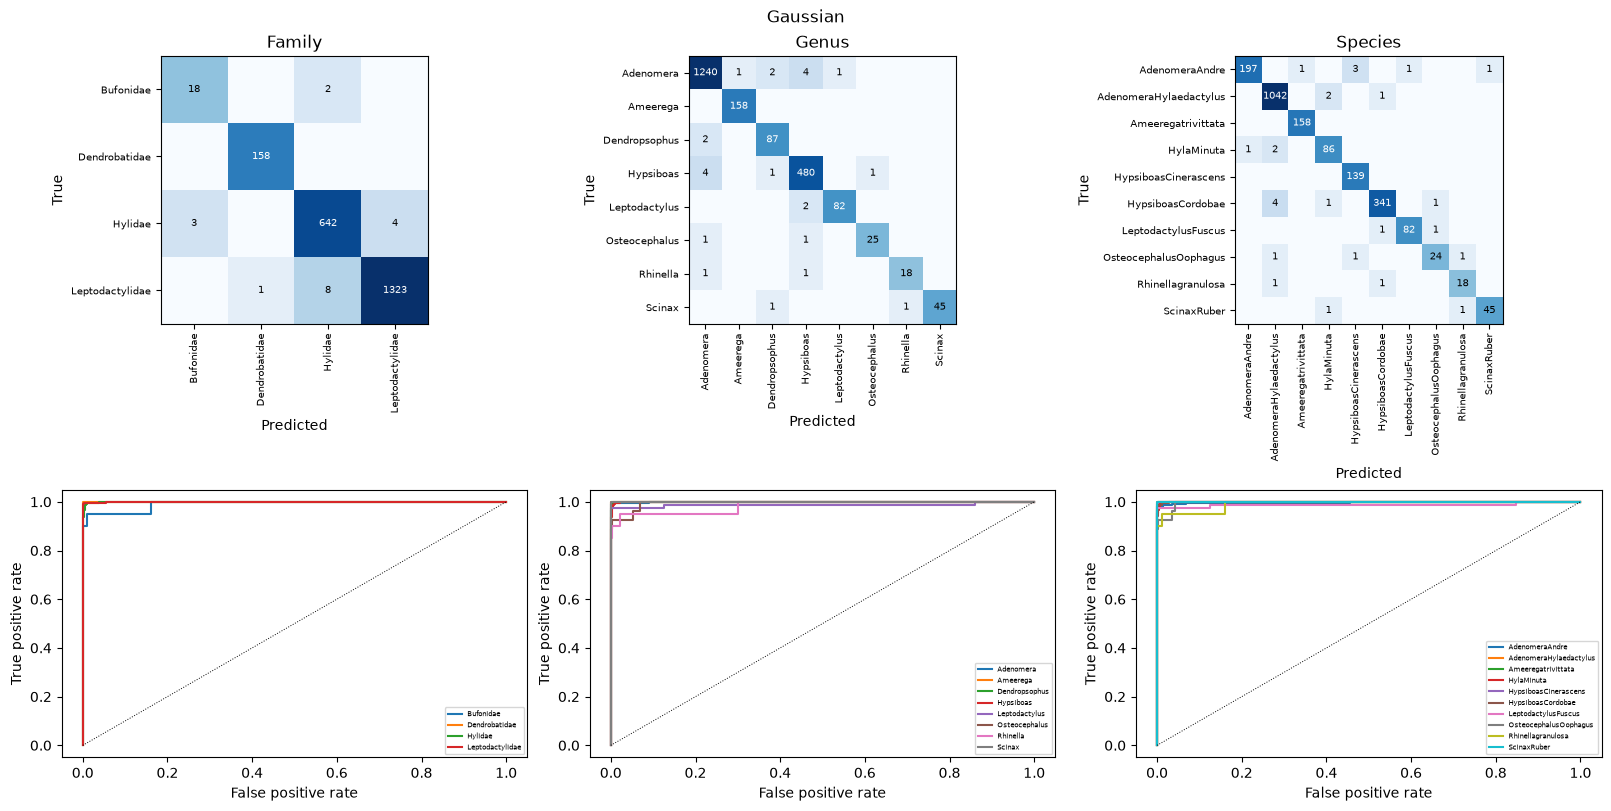

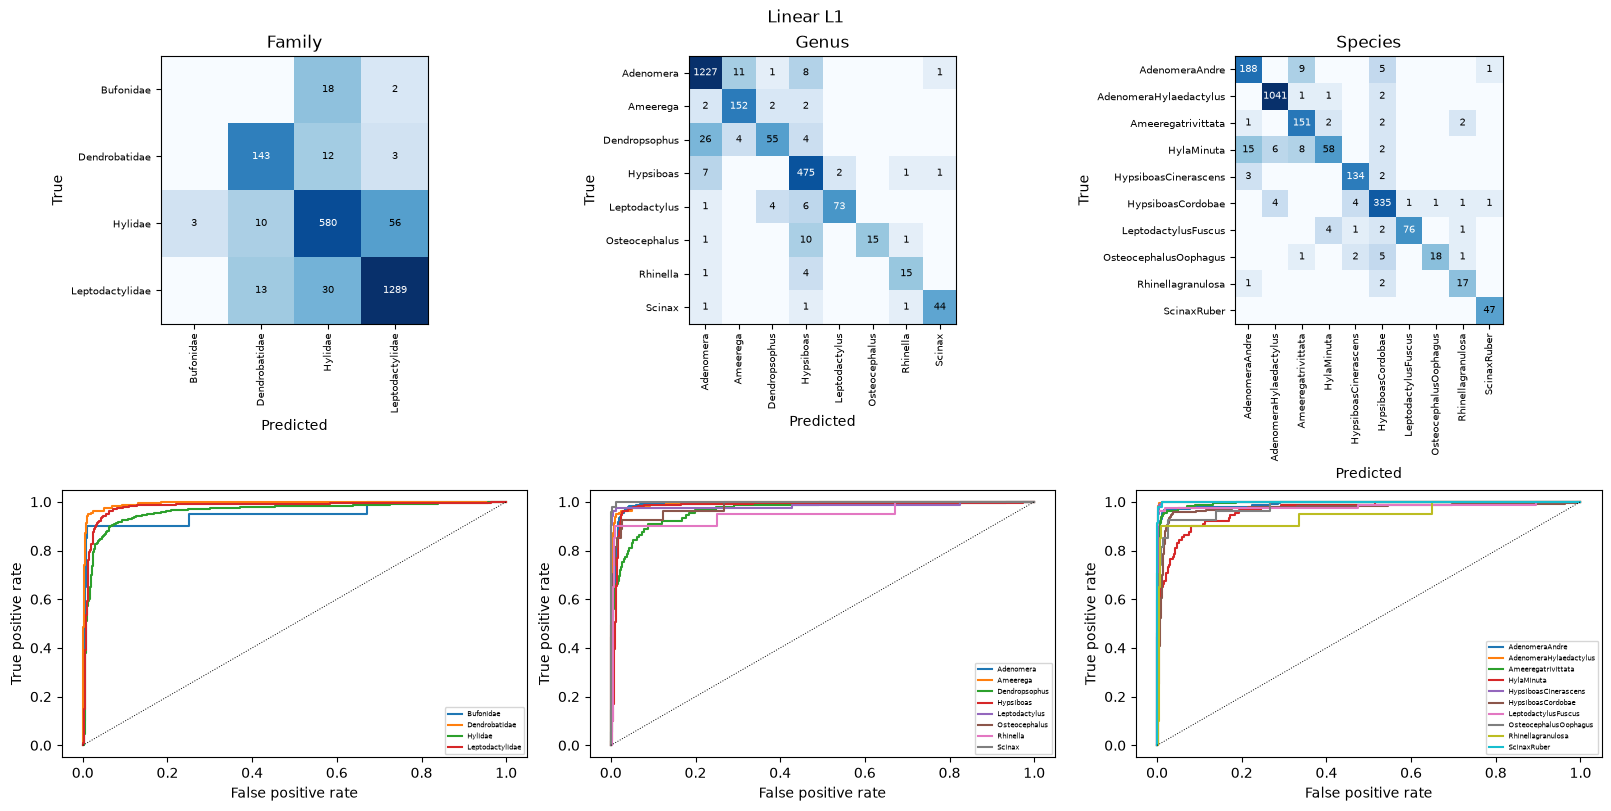

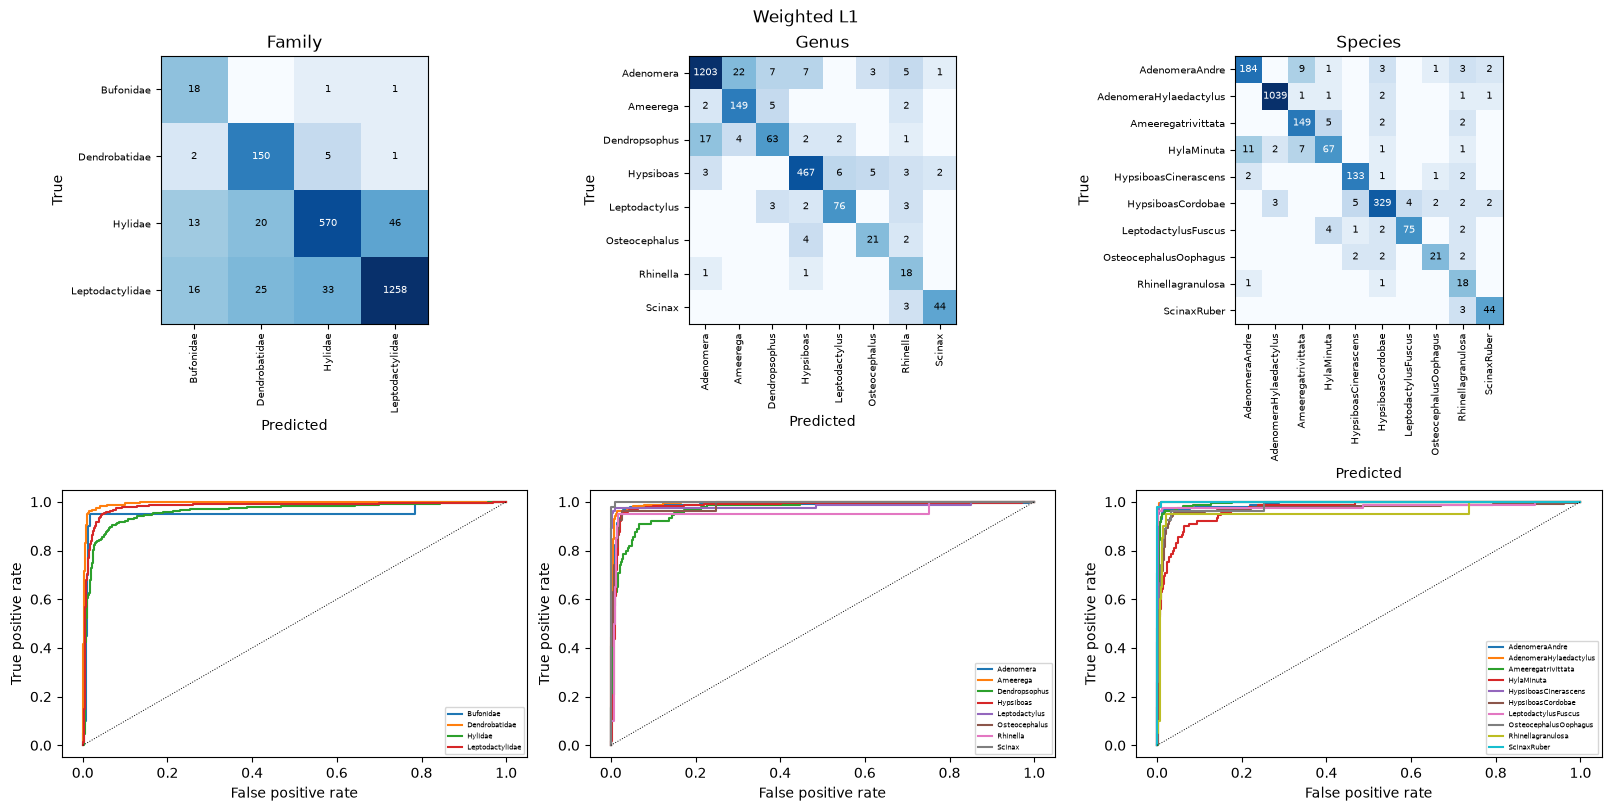

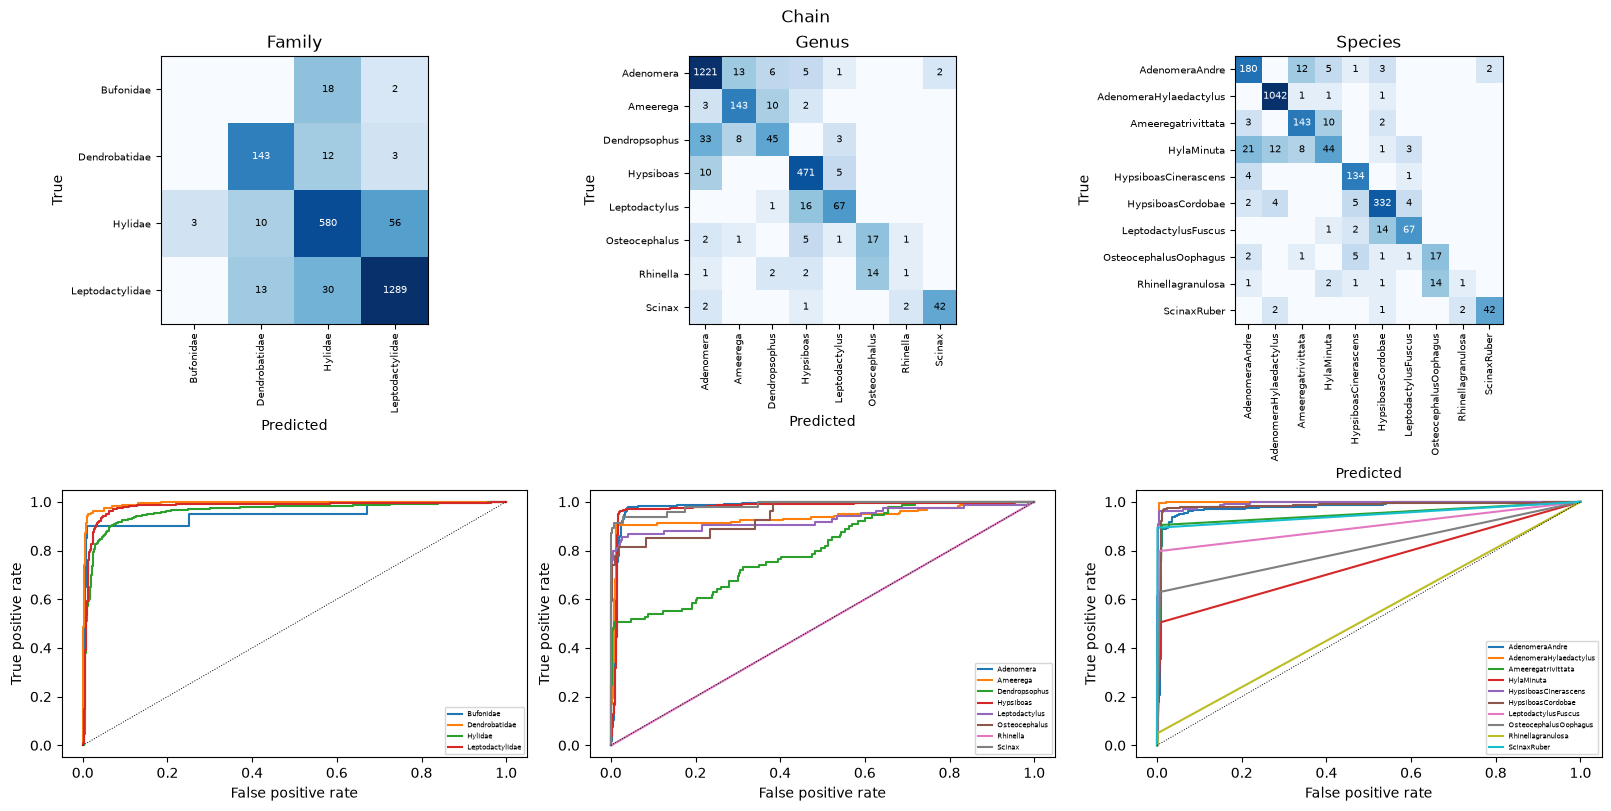

,Model,Target,Macro precision,Macro recall,Macro AUC
0,Gaussian,Family,0.9581,0.9706,0.9974
1,Gaussian,Genus,0.9780,0.9648,0.9957
2,Gaussian,Species,0.9689,0.9639,0.9973
3,Linear L1,Family,0.6806,0.6916,0.9702
4,Linear L1,Genus,0.9326,0.8314,0.9799
5,Linear L1,Species,0.9230,0.8881,0.9830
6,Weighted L1,Family,0.7589,0.9180,0.9712
7,Weighted L1,Genus,0.8323,0.8868,0.9815
8,Weighted L1,Species,0.8771,0.9008,0.9846
9,Chain,Family,0.6806,0.6916,0.9702


In [7]:
rows = []
for name, pred in predictions.items():
    fig, axes = plt.subplots(2, 3, figsize=(16, 8), layout='constrained')
    for j, target in enumerate(targets):
        truth = Y[target].iloc[test].to_numpy()
        classes = fits[name][j].classes_
        cm = confusion_matrix(truth, pred[:, j], labels=classes)
        ax = axes[0, j]
        ax.imshow(np.log1p(cm), cmap='Blues')
        for (i, k), value in np.ndenumerate(cm):
            if value: ax.text(k, i, str(value), ha='center', va='center', fontsize=7,
                              color='white' if np.log1p(value) > .6*np.log1p(cm.max()) else 'black')
        ax.set(xticks=range(len(classes)), yticks=range(len(classes)), xlabel='Predicted', ylabel='True', title=target)
        ax.set_xticklabels(classes, rotation=90, fontsize=7); ax.set_yticklabels(classes, fontsize=7)
        areas = []
        for k, cls in enumerate(classes):
            fpr, tpr, _ = roc_curve(truth == cls, decisions[name][j][:, k])
            axes[1,j].plot(fpr,tpr, label=cls)
            areas.append(auc(fpr,tpr))
        axes[1,j].plot([0,1],[0,1],'k:',lw=.7)
        axes[1,j].set(xlabel='False positive rate',ylabel='True positive rate')
        axes[1,j].legend(fontsize=5,loc='lower right')
        rows.append([name,target,precision_score(truth,pred[:,j],average='macro',zero_division=0),
                     recall_score(truth,pred[:,j],average='macro'),np.mean(areas)])
    fig.suptitle(name); plt.show()
display(pd.DataFrame(rows, columns=['Model','Target','Macro precision','Macro recall','Macro AUC']).round(4))

## 2. K-means clustering
### (a) Select k over 50 runs
I use all calls and the original MFCCs. For each seed I fit k-means for every k from 1 to 50 with one k-means++ initialization per candidate. I select the largest Calinski–Harabasz index, which compares between-cluster and within-cluster dispersion. The one-cluster fit provides total dispersion T. For k ≥ 2 and within-cluster dispersion W, the index is $[(T-W)/(k-1)]/[W/(n-k)]$. It is undefined at k = 1.

,Runs
Selected k,
2,50


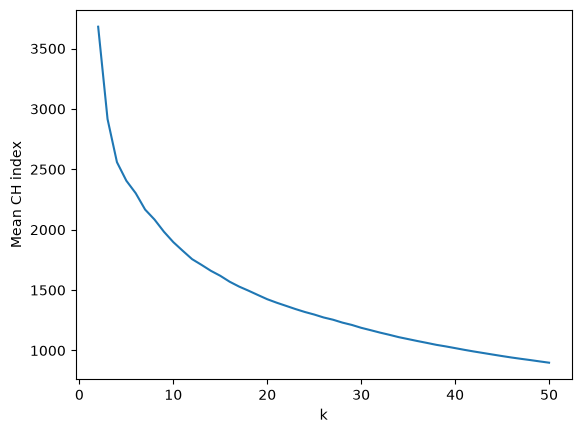

In [8]:
assignments, selections, ch_curves = [], [], []
with threadpool_limits(limits=1):
    for run in range(50):
        best_score = -np.inf
        curve = []
        for k in range(1,51):
            km = KMeans(n_clusters=k, n_init=1, random_state=seed+run).fit(X)
            if k == 1:
                total = km.inertia_
                continue
            within = km.inertia_
            score = ((total-within)/(k-1))/(within/(len(X)-k))
            curve.append(score)
            if score > best_score:
                best_score, best_k, best_labels = score, k, km.labels_.copy()
        assignments.append(best_labels)
        selections.append(best_k)
        ch_curves.append(curve)
display(pd.Series(selections).value_counts().sort_index().rename_axis('Selected k').to_frame('Runs'))
plt.plot(range(2,51), np.mean(ch_curves,axis=0)); plt.xlabel('k'); plt.ylabel('Mean CH index'); plt.show()

### (b) Majority label in each cluster
Within each cluster I take a separate majority vote for family, genus and species. In a tie I choose the alphabetically first class. The table shows the first run. I repeat the same vote for every run.

In [9]:
def majority_table(clusters):
    return Y.groupby(clusters).agg(lambda col: col.mode().iloc[0]).rename_axis('Cluster')
majorities = [majority_table(labels) for labels in assignments]
display(majorities[0].assign(Calls=np.bincount(assignments[0])))

,Family,Genus,Species,Calls
Cluster,,,,
0,Hylidae,Hypsiboas,HypsiboasCordobae,3597
1,Leptodactylidae,Adenomera,AdenomeraHylaedactylus,3598


### (c) Hamming distance, score and loss
I assign each call its cluster’s majority triplet and compare it with its observed labels. These are descriptive scores on the full data used to assign the cluster labels.

In [10]:
trials = []
for i, (labels, votes) in enumerate(zip(assignments, majorities)):
    trials.append({'Run': i+1, 'k': selections[i], **metrics(Y, votes.loc[labels].to_numpy())})
runs = pd.DataFrame(trials).set_index('Run')
display(runs.round(4))
display(runs.drop(columns='k').agg(['mean','std']).round(5))
print(f"Mean Hamming distance = {runs['Hamming distance'].mean():.5f} mismatched labels per call; sample SD = {runs['Hamming distance'].std(ddof=1):.5f}.")

,k,Exact match,Hamming distance,Hamming loss,Hamming score
Run,,,,,
1,2,0.6361,0.8956,0.2985,0.7015
2,2,0.6361,0.8956,0.2985,0.7015
3,2,0.6361,0.8956,0.2985,0.7015
4,2,0.6361,0.8956,0.2985,0.7015
5,2,0.6361,0.8956,0.2985,0.7015
6,2,0.6361,0.8956,0.2985,0.7015
7,2,0.6361,0.8956,0.2985,0.7015
8,2,0.6361,0.8956,0.2985,0.7015
9,2,0.6361,0.8956,0.2985,0.7015


,Exact match,Hamming distance,Hamming loss,Hamming score
mean,0.63614,0.89562,0.29854,0.70146
std,0.00000,0.00000,0.00000,0.00000


Mean Hamming distance = 0.89562 mismatched labels per call; sample SD = 0.00000.


## 3. ISLR 12.6.2
**(a)** Complete linkage merges 1 and 2 at 0.30. Their distance to 3 is max(0.40, 0.50) = 0.50, so 3 and 4 merge first at 0.45. The largest distance across the two pairs is 0.80, the final merge height.

**(b)** Single linkage also merges 1 and 2 at 0.30. Their nearest distance to 3 is 0.40, so 3 joins next. Observation 4 joins at min(0.70, 0.80, 0.45) = 0.45.

**(c)** Cutting the complete-linkage tree at two clusters gives {1, 2} and {3, 4}.

**(d)** Cutting the single-linkage tree at two clusters gives {1, 2, 3} and {4}.

**(e)** Swapping the left and right children changes the order of the leaves while preserving every merge and its height. The third plot shows one such ordering for (a).

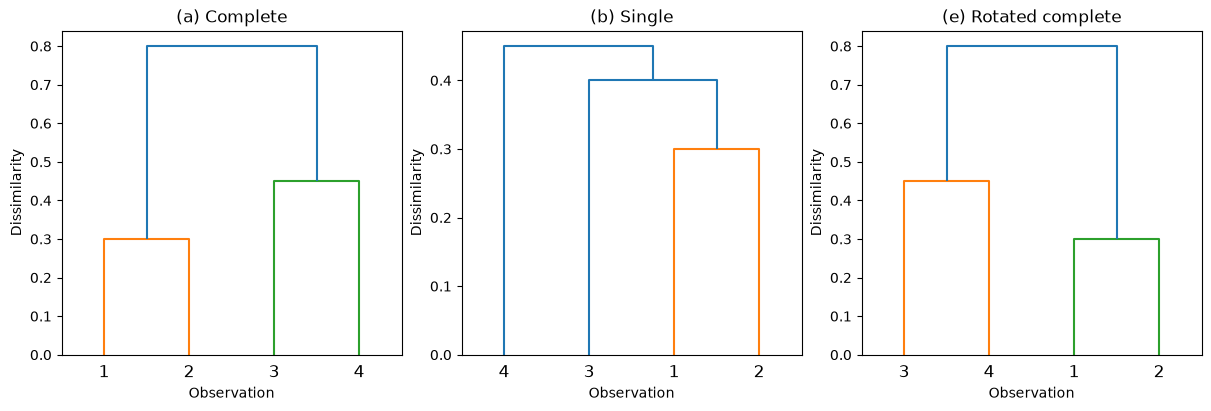

In [11]:
dist = np.array([[0,.3,.4,.7],[.3,0,.5,.8],[.4,.5,0,.45],[.7,.8,.45,0]])
complete = linkage(squareform(dist),method='complete')
single = linkage(squareform(dist),method='single')
rotated = complete.copy()
rotated[-1, :2] = rotated[-1, :2][::-1]
fig, axes = plt.subplots(1,3,figsize=(12,4),layout='constrained')
for ax,tree,title in zip(axes,[complete,single,rotated],['(a) Complete','(b) Single','(e) Rotated complete']):
    dendrogram(tree,labels=['1','2','3','4'],ax=ax)
    ax.set(title=title,xlabel='Observation',ylabel='Dissimilarity')
plt.show()